In [1]:
import pandas as pd
from sklearn.datasets import fetch_openml

credit = fetch_openml("credit-g", version=1, as_frame=True)
df = credit.frame
df.head()

,checking_status,duration,credit_history,purpose,credit_amount,savings_status,employment,installment_commitment,personal_status,other_parties,...,property_magnitude,age,other_payment_plans,housing,existing_credits,job,num_dependents,own_telephone,foreign_worker,class
0,<0,6,critical/other existing credit,radio/tv,1169,no known savings,>=7,4,male single,none,...,real estate,67,none,own,2,skilled,1,yes,yes,good
1,0<=X<200,48,existing paid,radio/tv,5951,<100,1<=X<4,2,female div/dep/mar,none,...,real estate,22,none,own,1,skilled,1,none,yes,bad
2,no checking,12,critical/other existing credit,education,2096,<100,4<=X<7,2,male single,none,...,real estate,49,none,own,1,unskilled resident,2,none,yes,good
3,<0,42,existing paid,furniture/equipment,7882,<100,4<=X<7,2,male single,guarantor,...,life insurance,45,none,for free,1,skilled,2,none,yes,good
4,<0,24,delayed previously,new car,4870,<100,1<=X<4,3,male single,none,...,no known property,53,none,for free,2,skilled,2,none,yes,bad


In [2]:
print(df.shape)
print(df.columns)

(1000, 21)
Index(['checking_status', 'duration', 'credit_history', 'purpose',
       'credit_amount', 'savings_status', 'employment',
       'installment_commitment', 'personal_status', 'other_parties',
       'residence_since', 'property_magnitude', 'age', 'other_payment_plans',
       'housing', 'existing_credits', 'job', 'num_dependents', 'own_telephone',
       'foreign_worker', 'class'],
      dtype='str')


In [3]:
df["class"].value_counts()
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 21 columns):
 #   Column                  Non-Null Count  Dtype   
---  ------                  --------------  -----   
 0   checking_status         1000 non-null   category
 1   duration                1000 non-null   int64   
 2   credit_history          1000 non-null   category
 3   purpose                 1000 non-null   category
 4   credit_amount           1000 non-null   int64   
 5   savings_status          1000 non-null   category
 6   employment              1000 non-null   category
 7   installment_commitment  1000 non-null   int64   
 8   personal_status         1000 non-null   category
 9   other_parties           1000 non-null   category
 10  residence_since         1000 non-null   int64   
 11  property_magnitude      1000 non-null   category
 12  age                     1000 non-null   int64   
 13  other_payment_plans     1000 non-null   category
 14  housing                 1000 non-nul

In [4]:
df["class"].value_counts()
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 21 columns):
 #   Column                  Non-Null Count  Dtype   
---  ------                  --------------  -----   
 0   checking_status         1000 non-null   category
 1   duration                1000 non-null   int64   
 2   credit_history          1000 non-null   category
 3   purpose                 1000 non-null   category
 4   credit_amount           1000 non-null   int64   
 5   savings_status          1000 non-null   category
 6   employment              1000 non-null   category
 7   installment_commitment  1000 non-null   int64   
 8   personal_status         1000 non-null   category
 9   other_parties           1000 non-null   category
 10  residence_since         1000 non-null   int64   
 11  property_magnitude      1000 non-null   category
 12  age                     1000 non-null   int64   
 13  other_payment_plans     1000 non-null   category
 14  housing                 1000 non-nul

In [5]:
df["class"].value_counts()

class
good    700
bad     300
Name: count, dtype: int64

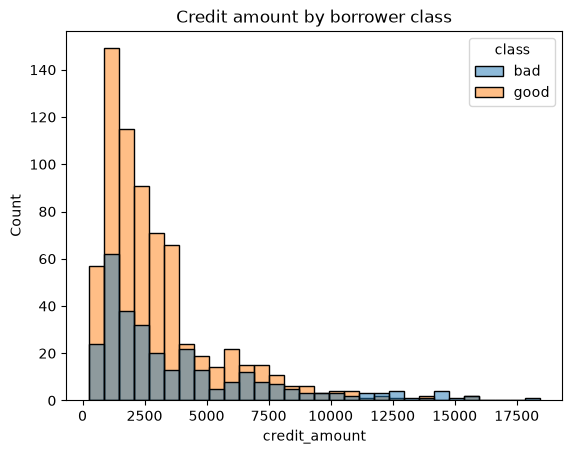

In [6]:
import matplotlib.pyplot as matplot
import seaborn as sb

sb.histplot(data=df, x="credit_amount", hue="class", bins=30)
matplot.title("Credit amount by borrower class")
matplot.show()

**Chart 1 – Credit amount:** The distribution is right-skewed: most loans are small
(roughly 0–4,000, peaking around 1,000–1,500), with a long tail of a few very large
loans. At small amounts, good borrowers clearly dominate (about 2.4 good per bad in the
peak). At larger amounts, the share of bad borrowers seems to grow, sometimes equalling
or exceeding good ones. However, there are very few loans above 10,000, so this
pattern is uncertain.


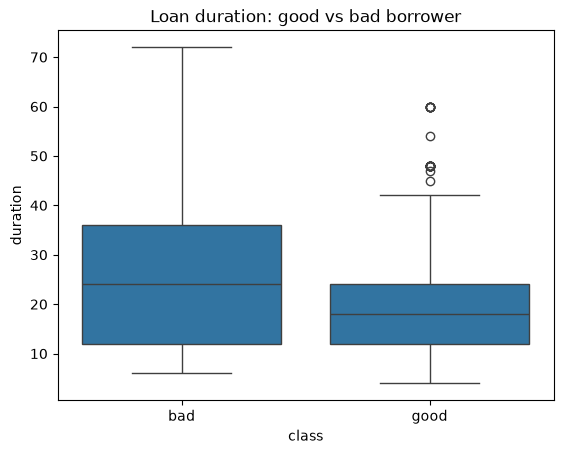

In [7]:
sb.boxplot(data=df, x="class", y="duration")
matplot.title("Loan duration: good vs bad borrower")
matplot.show()

**Chart 2 – Loan duration:** Bad borrowers tend to have longer loans: their median
duration is higher and their durations are more spread out. This does not mean there are more bad borrowers, only that their loans tend to be longer.

In [8]:
df.groupby("class")["duration"].median()

class
bad     24.0
good    18.0
Name: duration, dtype: float64

**Median loan duration by class - Pandas equivalent of SQL'S Group By:** Typical "Bad Borrower" had a loan of: 24 months (2 years) and Typical "Good Borrower" had a loan of: 18 months (1.5 years). Approximately 6 months longer for bad compared to good borrower. 33% longer

In [11]:
df["duration"].corr(df["credit_amount"])

np.float64(0.6249841983009837)

**Correlation** ~ 0.62 - bigger loans tend to be longer loans, approximately. Because they move together we cannot, yet, tell which one drives risk. The SHAP will help us later..

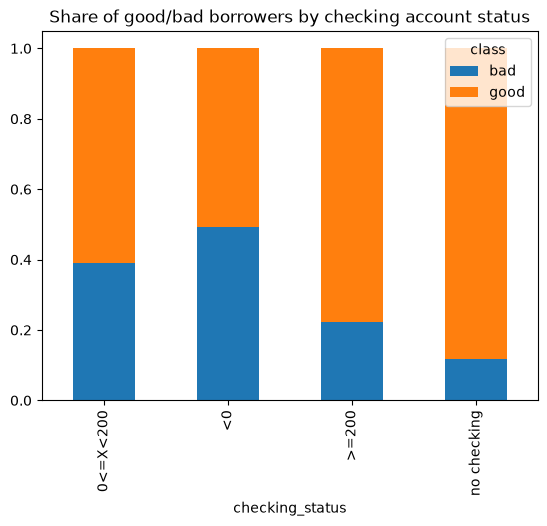

In [13]:
pd.crosstab(df["checking_status"], df["class"], normalize="index").plot(kind="bar", stacked=True)
matplot.title("Share of good/bad borrowers by checking account status")
matplot.show()

**Checking status** - By the experiment used with normalize = "index", we come to conlcusion that the share of bad borrowers are at "<0" ~ 49%, which is the highest, the lowest share of bad borrower sits at "no checking" group, with ~12%. "#0<=X<200" ~ 39% and "#>=200" ~ 22%.

**Something**


In [15]:
pd.crosstab(df["checking_status"], df["class"])


class,bad,good
checking_status,,
0<=X<200,105,164
<0,135,139
>=200,14,49
no checking,46,348


In [17]:
pd.crosstab(df["checking_status"], df["class"], normalize="index").round(2)


class,bad,good
checking_status,,
0<=X<200,0.39,0.61
<0,0.49,0.51
>=200,0.22,0.78
no checking,0.12,0.88


## Hypotheses (to test later)
1. Larger credit amounts are associated with a higher share of bad borrowers.
2. Longer loan durations are associated with a higher risk of being a bad borrower.
3. Applicants with a negative checking balance are more likely to be bad borrowers.